# Frozen RoBERTa baseline for ternary AI-text detection

1. Extract a English `academic` + `wiki` slice from the DetectRL-X ternary JSON. Keep the dataset's supplied `train` and `test` partitions.
2. Split the supplied training partition into train/validation groups by `pair_id`.
3. Extract frozen `roberta-base` mean-pooled embeddings.
4. Train Logistic Regression on those embeddings.
5. Report macro-F1, per-class precision/recall, confusion matrix, and qualitative examples.

**Dataset:** `trinary_general_256_open` in DetectRL-X , which is 256-token truncated.  
**Data Sampling:** up to 1,000 source pairs per domain in train and 250 per domain in test. The extraction script balances sampling across LLMs within each domain.

> Note: this is not fine-tuning RoBERTa. The transformer weights remain frozen; only the Logistic Regression classifier is fitted.


## 0. Runtime setup

In Colab, select **Runtime → Change runtime type → T4 GPU** if available.

## 1. Download the dataset and extraction script


In [2]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import os

REPO_ID = "WUJUNCHAO/DetectRL-X"
DATA_FILE = "Ternary/trinary_general_256_open.json"

json_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=DATA_FILE,
    repo_type="dataset",
)
print("Dataset:", json_path)

# Upload extract_ternary_subset.py to the Colab session, or place it in the current directory.
from google.colab import files
uploaded = files.upload()  # choose extract_ternary_subset.py


Dataset: /root/.cache/huggingface/hub/datasets--WUJUNCHAO--DetectRL-X/snapshots/ccc9a0a74793dd3448e0da1650b430f5df1b0402/Ternary/trinary_general_256_open.json


Saving extract_ternary_subset.py to extract_ternary_subset.py


## 2. Extract a balanced slice

The script samples round-robin across model groups to create a balanced slice with 1,200 observations in each domain.

In [3]:
!python -m pip install --user ijson

OUTPUT_CSV = "ternary_academic_wiki_256.csv"

!python extract_ternary_subset.py "$json_path" --lang english --domains academic,wiki --train-per-domain 1000 --test-per-domain 250 --seed 42 --out "$OUTPUT_CSV"

import pandas as pd
df = pd.read_csv(OUTPUT_CSV)
print(df.shape)
display(df.groupby(["split", "domain", "label"]).size().unstack(fill_value=0))
display(df.groupby(["split", "domain", "model"]).size().unstack(fill_value=0))


Wrote 7,500 text rows from 2,500 source pairs to ternary_academic_wiki_256.csv
Selected source pairs by split/domain:
  test/academic: 250
  test/wiki: 250
  train/academic: 1,000
  train/wiki: 1,000
Text rows by label: {'human': 2500, 'ai_generated': 2500, 'ai_refined': 2500}
Text rows by split: {'train': 6000, 'test': 1500}
Text rows by domain: {'wiki': 3750, 'academic': 3750}
(7500, 7)


label           ai_generated  ai_refined  human
split domain                                   
test  Academic           250         250    250
      Wiki               250         250    250
train Academic          1000        1000   1000
      Wiki              1000        1000   1000

model           deepseek-v3  gemini-2.5-flash  gpt-4o  qwen-max
split domain                                                   
test  Academic          189               189     186       186
      Wiki              189               189     186       186
train Academic          750               750     750       750
      Wiki              750               750     750       750

## 3. Validation Split

The source `test` split remains untouched. Validation is created only from source `train`, with all rows sharing a `pair_id` assigned to the same side.

If a source observation is missing one of its three text fields, it contributes only the available labels. Check the class distribution before proceeding.

In [4]:
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

required = {"text", "label", "pair_id", "lang", "model", "domain", "split"}
missing = required - set(df.columns)
assert not missing, f"Missing columns: {missing}"

df = df.dropna(subset=["text", "label", "pair_id"]).copy()
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(str)
df["pair_id"] = df["pair_id"].astype(str)
df["split"] = df["split"].astype(str).str.lower()

print("Overall label counts:")
display(df["label"].value_counts())
print("Supplied split × label:")
display(pd.crosstab(df["split"], df["label"]))

train_all = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

assert len(train_all) > 0 and len(test_df) > 0, "Need non-empty train and test partitions."

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
fit_idx, val_idx = next(gss.split(train_all, groups=train_all["pair_id"]))

fit_df = train_all.iloc[fit_idx].reset_index(drop=True)
val_df = train_all.iloc[val_idx].reset_index(drop=True)

fit_pairs = set(fit_df["pair_id"])
val_pairs = set(val_df["pair_id"])
test_pairs = set(test_df["pair_id"])
assert fit_pairs.isdisjoint(val_pairs)
assert fit_pairs.isdisjoint(test_pairs)
assert val_pairs.isdisjoint(test_pairs)

for name, part in [("fit", fit_df), ("validation", val_df), ("test", test_df)]:
    print(f"\\n{name}: {len(part):,} texts, {part['pair_id'].nunique():,} pairs")
    display(part["label"].value_counts())


Overall label counts:


,count
label,
human,2500
ai_generated,2500
ai_refined,2500


Supplied split × label:


label,ai_generated,ai_refined,human
split,,,
test,500,500,500
train,2000,2000,2000


\nfit: 5,100 texts, 1,700 pairs


,count
label,
human,1700
ai_generated,1700
ai_refined,1700


\nvalidation: 900 texts, 300 pairs


,count
label,
human,300
ai_generated,300
ai_refined,300


\ntest: 1,500 texts, 500 pairs


,count
label,
human,500
ai_generated,500
ai_refined,500


## 4. Load frozen RoBERTa and extract embeddings

We use attention-mask-aware mean pooling over the final hidden states. This produces one fixed-size vector per text. RoBERTa is in evaluation mode and gradients are disabled.

The source dataset is already truncated to 256 tokens, and the tokenizer is also configured with `max_length=256` as a safety limit.

In [5]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

MODEL_NAME = "roberta-base"
MAX_LENGTH = 256
BATCH_SIZE = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device)
encoder.eval()
for param in encoder.parameters():
    param.requires_grad = False

class TextDataset(Dataset):
    def __init__(self, texts):
        self.texts = list(texts)
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        return self.texts[idx]

@torch.inference_mode()
def embed_texts(texts, batch_size=BATCH_SIZE):
    loader = DataLoader(TextDataset(texts), batch_size=batch_size, shuffle=False)
    all_embeddings = []
    for batch_texts in tqdm(loader, leave=False):
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt",
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        outputs = encoder(**encoded)
        hidden = outputs.last_hidden_state
        mask = encoded["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embeddings.append(pooled.cpu().numpy().astype("float32"))
    return np.concatenate(all_embeddings, axis=0)

X_fit = embed_texts(fit_df["text"])
X_val = embed_texts(val_df["text"])
X_test = embed_texts(test_df["text"])

y_fit = fit_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Embedding shapes:", X_fit.shape, X_val.shape, X_test.shape)


Device: cuda


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

  0%|          | 0/319 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

Embedding shapes: (5100, 768) (900, 768) (1500, 768)


## 5. Logical Regression classifier and evaluate on validation

Validation accuracy: 0.9333
Validation macro-F1: 0.9333
              precision    recall  f1-score   support

ai_generated     0.9700    0.9700    0.9700       300
  ai_refined     0.9003    0.9033    0.9018       300
       human     0.9298    0.9267    0.9282       300

    accuracy                         0.9333       900
   macro avg     0.9334    0.9333    0.9333       900
weighted avg     0.9334    0.9333    0.9333       900



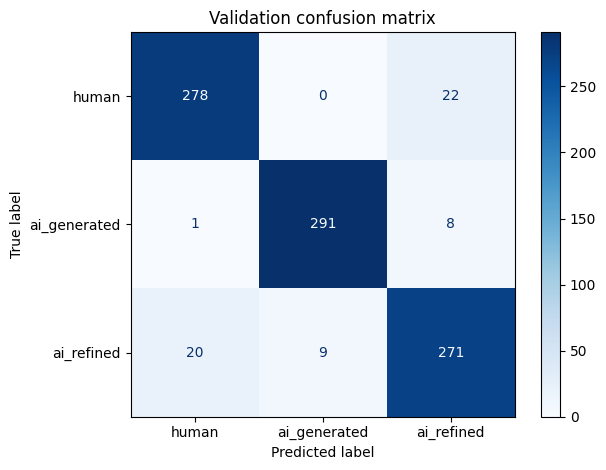

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)
import matplotlib.pyplot as plt

classifier = LogisticRegression(
    max_iter=2000,
    C=1.0,
    class_weight="balanced",
    random_state=42,
)
classifier.fit(X_fit, y_fit)

val_pred = classifier.predict(X_val)
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Validation macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 4))
print(classification_report(y_val, val_pred, digits=4, zero_division=0))

labels = ["human", "ai_generated", "ai_refined"]
ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, labels=labels, display_labels=labels,
    cmap="Blues", values_format="d"
)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()


## 6. Final evaluation on the held-out supplied test split

After checking the validation results, fit the classifier on all supplied training data (fit + validation) and evaluate once on the supplied test split.

Test accuracy: 0.882
Test macro-F1: 0.8837
              precision    recall  f1-score   support

ai_generated     0.9880    0.8260    0.8998       500
  ai_refined     0.7795    0.9120    0.8406       500
       human     0.9135    0.9080    0.9107       500

    accuracy                         0.8820      1500
   macro avg     0.8937    0.8820    0.8837      1500
weighted avg     0.8937    0.8820    0.8837      1500



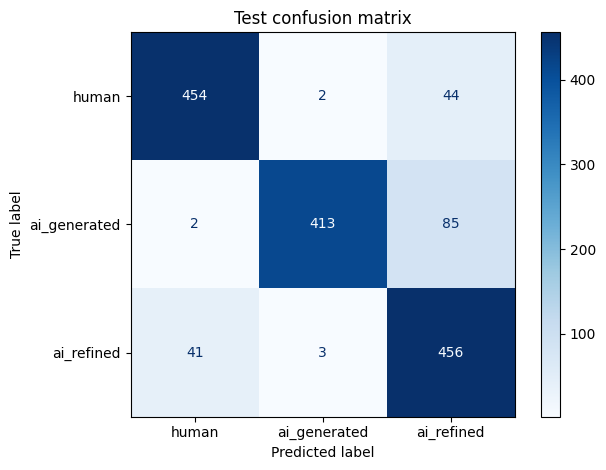

Error counts by true label and predicted label:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,413,85,2
ai_refined,3,456,41
human,2,44,454


Accuracy by domain:


,count,mean
domain,,
Academic,750,0.885333
Wiki,750,0.878667


Accuracy by model:


,count,mean
model,,
gpt-4o,372,0.870968
deepseek-v3,378,0.873016
qwen-max,372,0.873656
gemini-2.5-flash,378,0.910053


In [9]:
X_train_full = np.concatenate([X_fit, X_val], axis=0)
y_train_full = np.concatenate([y_fit, y_val], axis=0)

final_classifier = LogisticRegression(
    max_iter=2000,
    C=1.0,
    class_weight="balanced",
    random_state=42,
)
final_classifier.fit(X_train_full, y_train_full)

test_pred = final_classifier.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Test macro-F1:", round(f1_score(y_test, test_pred, average="macro"), 4))
print(classification_report(y_test, test_pred, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=labels, display_labels=labels,
    cmap="Blues", values_format="d"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

results = test_df.copy()
results["prediction"] = test_pred
results["correct"] = results["label"] == results["prediction"]

print("Error counts by true label and predicted label:")
display(pd.crosstab(results["label"], results["prediction"]))

print("Accuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))
print("Accuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]).sort_values("mean"))


## 8. Save predictions and experiment artifacts

In [10]:
results.to_csv("test_predictions_roberta_frozen_lr.csv", index=False)

import joblib
joblib.dump(final_classifier, "roberta_frozen_logreg.joblib")

# Save embeddings and split identifiers so you can rerun classifier experiments
# without extracting RoBERTa embeddings again.
np.savez_compressed(
    "roberta_frozen_embeddings.npz",
    X_fit=X_fit, X_val=X_val, X_test=X_test,
    y_fit=y_fit, y_val=y_val, y_test=y_test,
)

from google.colab import files
files.download("test_predictions_roberta_frozen_lr.csv")
files.download("roberta_frozen_logreg.joblib")
files.download("roberta_frozen_embeddings.npz")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Qualitative Analysis

In [11]:
import numpy as np
from IPython.display import display

#  QUALITATIVE ANALYSIS

results = results.copy()
results["word_count"] = (
    results["text"].fillna("").str.split().str.len()
)
results["correct"] = (
    results["label"] == results["prediction"]
)

# incorrect classifications

errors = results[~results["correct"]].copy()

selected_errors = []

for (actual, predicted), group in errors.groupby(
    ["label", "prediction"]
):
    # shortest incorrect example
    short = group.nsmallest(1, "word_count").copy()
    short["selection"] = "Shortest incorrect"

    # longest incorrect example
    long = group.drop(short.index).nlargest(
        1, "word_count"
    ).copy()
    long["selection"] = "Longest incorrect"

    # random incorrect example
    remaining = group.drop(
        short.index.union(long.index)
    )
    random_ex = remaining.sample(
        n=min(1, len(remaining)),
        random_state=42
    ).copy()
    random_ex["selection"] = "Random incorrect"

    selected_errors.extend([short, long, random_ex])

incorrect_examples = pd.concat(
    selected_errors, ignore_index=True
)

# correct classification

correct = results[results["correct"]].copy()

correct_examples = (
    correct.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
    .copy()
)

correct_examples["selection"] = "Random correct"

# combine & display

qualitative_examples = pd.concat(
    [incorrect_examples, correct_examples],
    ignore_index=True
)

for _, row in qualitative_examples.iterrows():
    print("\n" + "=" * 80)
    print("selection:", row["selection"])
    print("actual:", row["label"])
    print("predicted:", row["prediction"])
    print("domain:", row["domain"])
    print("model:", row["model"])
    print("ID:", row["pair_id"])
    print("word count:", row["word_count"])
    print("\nTEXT:")
    print(row["text"])


selection: Shortest incorrect
actual: ai_generated
predicted: ai_refined
domain: Academic
model: gpt-4o
ID: 111349
word count: 118

TEXT:
The research detailed the synthesis and characterization of salts derived from 1-butyl-3-methylimidazolium ([bm-Im]) and transition metal chlorides, specifically FeCl3, CoCl2, NiCl2, and CuCl2. The synthetic approach began with the preparation of [bm-Im]FeCl4, achieved through a controlled 3-hour reaction at ambient temperature. To ensure the purity of the product, the crude material was meticulously washed with diethyl ether, followed by vacuum drying. This process resulted in high-purity [bm-Im]FeCl4, whose molecular integrity was vital for subsequent experiments. Extending this methodology, the researchers synthesized additional complexes by reacting [bm-Im]Cl with other metal chlorides (CoCl2, NiCl2, CuCl2) in a 2:1 molar ratio. These reactions were carried out in ethanol, a solvent selected for its ability to facilitate homogeneous mixing of th